# LangGraph 子图：组合、通信、流式观察与持久化

> 适用版本：本项目锁定的 **LangGraph 1.1.2**。本教程使用纯本地、确定性示例，不调用模型、网络或外部服务。

子图（subgraph）是已经编译的 LangGraph 图，它可以被父图复用。子图适合封装一组节点、隔离内部 State、拆分团队职责，以及构建多智能体系统。

官方文档：[Subgraphs](https://docs.langchain.com/oss/python/langgraph/use-subgraphs)

## 学习目标

完成本教程后，你将能够：

1. 根据父子图是否共享 State key，选择直接挂载或适配器调用；
2. 区分父子图共享 channel 与子图私有 channel；
3. 用 `get_graph(xray=True)` 和 `stream(subgraphs=True)` 观察嵌套结构；
4. 理解 `checkpointer=None`、`True`、`False` 的持久化边界；
5. 在子图暂停时检查嵌套 `StateSnapshot`，并从父图恢复执行。

## 总体流程

```mermaid
flowchart LR
    Input[父图输入] --> ParentStart[父图] 
    ParentStart --> Shared{父子图是否共享 State key?}
    Shared -->|是| Direct[将编译后的子图直接作为节点]
    Shared -->|否| Adapter[父节点转换输入并调用子图]

    subgraph Child[子图内部]
        ChildInput[共享输入] --> ChildNode1[子图节点 1]
        ChildNode1 --> Private[子图私有字段]
        Private --> ChildNode2[子图节点 2]
        ChildNode2 --> ChildOutput[共享输出]
    end

    Direct --> ChildInput
    Adapter --> ChildInput
    ChildOutput --> ParentFinish[父图继续执行]
    ParentFinish --> Output[父图输出]
```

核心判断不是“子图有多少节点”，而是**父图与子图通过哪些 State channel 通信**。

In [1]:
import operator
from importlib.metadata import version
from pprint import pprint
from typing import Annotated, TypedDict

from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph
from langgraph.types import Command, interrupt

installed_langgraph_version = version("langgraph")
print("当前 LangGraph 版本：", installed_langgraph_version)
assert installed_langgraph_version == "1.1.2"

当前 LangGraph 版本： 1.1.2


## 1. 共享 State：把编译后的子图直接作为节点

当父图与子图共享 State key 时，可以把编译后的子图直接传给 `add_node()`。LangGraph 会把父图的同名 channel 作为子图输入，并把子图的同名输出合并回父图。

本例中：

- `topic`、`child_result` 是共享 channel；
- `child_private` 只存在于子图 State；
- `final_result` 只存在于父图 State。

In [2]:
class SharedChildState(TypedDict):
    topic: str
    child_private: str
    child_result: str


class SharedParentState(TypedDict):
    topic: str
    child_result: str
    final_result: str


def normalize_child(state: SharedChildState) -> dict:
    normalized_topic = state["topic"].strip()
    return {
        "topic": normalized_topic,
        "child_private": normalized_topic.upper(),
    }


def compose_child(state: SharedChildState) -> dict:
    return {"child_result": f"子图处理：{state['child_private']}"}


shared_child_builder = StateGraph(SharedChildState)
shared_child_builder.add_node("normalize_child", normalize_child)
shared_child_builder.add_node("compose_child", compose_child)
shared_child_builder.add_edge(START, "normalize_child")
shared_child_builder.add_edge("normalize_child", "compose_child")
shared_child_builder.add_edge("compose_child", END)
shared_child_graph = shared_child_builder.compile(name="shared_child_graph")


def finish_parent(state: SharedParentState) -> dict:
    return {"final_result": f"父图收到：{state['child_result']}"}


shared_parent_builder = StateGraph(SharedParentState)
shared_parent_builder.add_node("child", shared_child_graph)
shared_parent_builder.add_node("finish_parent", finish_parent)
shared_parent_builder.add_edge(START, "child")
shared_parent_builder.add_edge("child", "finish_parent")
shared_parent_builder.add_edge("finish_parent", END)
shared_parent_graph = shared_parent_builder.compile(name="shared_parent_graph")

### 1.1 完整运行结果

先完整输出父图的原始返回字典。注意观察共享字段的变化，以及最终结果中是否出现 `child_private`。

In [3]:
shared_input: SharedParentState = {
    "topic": "  LangGraph 子图  ",
    "child_result": "",
    "final_result": "",
}
shared_result = shared_parent_graph.invoke(shared_input)

print("父图 invoke() 的完整原始结果：")
pprint(shared_result, sort_dicts=False)

父图 invoke() 的完整原始结果：
{'topic': 'LangGraph 子图',
 'child_result': '子图处理：LANGGRAPH 子图',
 'final_result': '父图收到：子图处理：LANGGRAPH 子图'}


In [4]:
assert shared_result == {
    "topic": "LangGraph 子图",
    "child_result": "子图处理：LANGGRAPH 子图",
    "final_result": "父图收到：子图处理：LANGGRAPH 子图",
}
assert "child_private" not in shared_result
print("机制验证通过：共享 channel 已写回父图，子图私有 channel 未泄漏。")

机制验证通过：共享 channel 已写回父图，子图私有 channel 未泄漏。


### 结果解读

- 子图的 `normalize_child` 更新了共享的 `topic`，所以父图看到去除空白后的值；
- 子图通过私有的 `child_private` 在两个内部节点之间传值；
- 子图完成时，只有父图 schema 中存在的共享 channel 会被写回；
- 父图不需要知道子图内部有多少节点，只依赖共享 State 接口。

## 2. 不同 State schema：在父节点中调用子图并转换数据

如果父图与子图没有共享 key，或调用前后需要重命名、裁剪、校验数据，就使用一个普通父节点作为适配器：

1. 把父 State 转换成子图输入；
2. 调用 `subgraph.invoke()`；
3. 把子图输出转换成父 State 更新。

In [5]:
class AdapterChildState(TypedDict):
    source_text: str
    normalized_text: str
    summary: str


class AdapterParentState(TypedDict):
    query: str
    answer: str


def clean_text(state: AdapterChildState) -> dict:
    normalized = " ".join(state["source_text"].strip().split())
    return {"normalized_text": normalized}


def summarize_text(state: AdapterChildState) -> dict:
    return {"summary": f"子图摘要：{state['normalized_text']}"}


adapter_child_builder = StateGraph(AdapterChildState)
adapter_child_builder.add_node("clean_text", clean_text)
adapter_child_builder.add_node("summarize_text", summarize_text)
adapter_child_builder.add_edge(START, "clean_text")
adapter_child_builder.add_edge("clean_text", "summarize_text")
adapter_child_builder.add_edge("summarize_text", END)
adapter_child_graph = adapter_child_builder.compile(name="adapter_child_graph")


def call_adapter_child(state: AdapterParentState) -> dict:
    child_input: AdapterChildState = {
        "source_text": state["query"],
        "normalized_text": "",
        "summary": "",
    }
    child_output = adapter_child_graph.invoke(child_input)
    return {"answer": child_output["summary"]}


adapter_parent_builder = StateGraph(AdapterParentState)
adapter_parent_builder.add_node("call_adapter_child", call_adapter_child)
adapter_parent_builder.add_edge(START, "call_adapter_child")
adapter_parent_builder.add_edge("call_adapter_child", END)
adapter_parent_graph = adapter_parent_builder.compile(name="adapter_parent_graph")

In [6]:
adapter_input: AdapterParentState = {
    "query": "  LangGraph    子图通信  ",
    "answer": "",
}
adapter_result = adapter_parent_graph.invoke(adapter_input)

print("不同 schema 的父图完整原始结果：")
pprint(adapter_result, sort_dicts=False)

不同 schema 的父图完整原始结果：
{'query': '  LangGraph    子图通信  ', 'answer': '子图摘要：LangGraph 子图通信'}


In [7]:
assert adapter_result == {
    "query": "  LangGraph    子图通信  ",
    "answer": "子图摘要：LangGraph 子图通信",
}
assert set(adapter_result) == {"query", "answer"}
print("机制验证通过：适配器完成了父子 State 的双向映射。")

机制验证通过：适配器完成了父子 State 的双向映射。


### 结果解读

适配器让父图只依赖 `query → answer` 接口，而子图可以独立使用 `source_text`、`normalized_text`、`summary`。代价是父节点需要显式维护映射逻辑；优点是两个 schema 可以独立演进。

## 3. 用 `get_graph(xray=True)` 展开子图结构

普通 `get_graph()` 把整个子图视为一个节点；`xray=True` 会把可静态发现的子图内部节点展开。下面先完整输出两个 `Graph` 对象。

get_graph() 的完整原始对象：
Graph(nodes={'__end__': Node(id='__end__', name='__end__', data=None, metadata=None),
             '__start__': Node(id='__start__', name='__start__', data=RunnableCallable(tags=None, recurse=True, explode_args=False, func_accepts={}), metadata=None),
             'child': Node(id='child', name='child', data=<langgraph.graph.state.CompiledStateGraph object at 0x1155c0050>, metadata=None),
             'finish_parent': Node(id='finish_parent', name='finish_parent', data=finish_parent(tags=None, recurse=True, explode_args=False, func_accepts={}), metadata=None)},
      edges=[Edge(source='__start__', target='child', data=None, conditional=False),
             Edge(source='child', target='finish_parent', data=None, conditional=False),
             Edge(source='finish_parent', target='__end__', data=None, conditional=False)])

get_graph(xray=True) 的完整原始对象：
Graph(nodes={'__end__': Node(id='__end__', name='__end__', data=None, metadata=None),
             '__start__': No

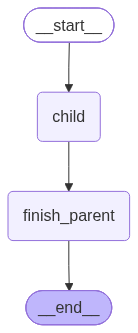

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	child(child)
	finish_parent(finish_parent)
	__end__([<p>__end__</p>]):::last
	__start__ --> child;
	child --> finish_parent;
	finish_parent --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc


xray 结构的完整 Mermaid：
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	finish_parent(finish_parent)
	__end__([<p>__end__</p>]):::last
	__start__ --> child\3anormalize_child;
	child\3acompose_child --> finish_parent;
	finish_parent --> __end__;
	subgraph child
	child\3anormalize_child(normalize_child)
	child\3acompose_child(compose_child)
	child\3anormalize_child --> child\3acompose_child;
	end
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



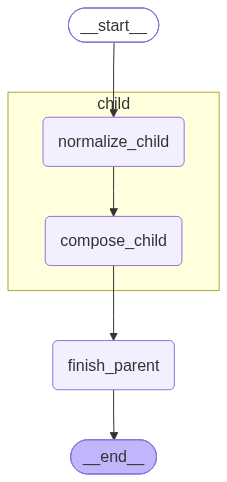

In [28]:
from IPython.core.display import Image

plain_graph = shared_parent_graph.get_graph()
xray_graph = shared_parent_graph.get_graph(xray=True)

print("get_graph() 的完整原始对象：")
pprint(plain_graph)
print("\nget_graph(xray=True) 的完整原始对象：")
pprint(xray_graph)
print("\n普通结构的完整 Mermaid：")
display(Image(plain_graph.draw_mermaid_png()))
print(plain_graph.draw_mermaid())
print("\nxray 结构的完整 Mermaid：")
print(xray_graph.draw_mermaid())
display(Image(xray_graph.draw_mermaid_png()))


In [9]:
plain_node_names = set(plain_graph.nodes)
xray_node_names = set(xray_graph.nodes)

print("普通节点名全集：")
pprint(plain_node_names)
print("xray 节点名全集：")
pprint(xray_node_names)

assert "child" in plain_node_names
assert "child:normalize_child" in xray_node_names
assert "child:compose_child" in xray_node_names
assert "child" not in xray_node_names
print("机制验证通过：xray 已把直接挂载的子图展开。")

普通节点名全集：
{'finish_parent', '__start__', '__end__', 'child'}
xray 节点名全集：
{'__end__',
 '__start__',
 'child:compose_child',
 'child:normalize_child',
 'finish_parent'}
机制验证通过：xray 已把直接挂载的子图展开。


## 4. 用 namespace 区分父图与子图事件

默认流只关注根图。传入 `subgraphs=True` 后，子图内部事件也会进入同一个流。本项目的 LangGraph 1.1.2 支持显式使用 `version="v2"`，每个事件都包含：

- `type`：事件类型；
- `ns`：事件来源的 namespace；
- `data`：本次事件的完整数据。

根图 namespace 是空元组 `()`；子图 namespace 包含 `节点名:运行时 ID`。运行时 ID 每次执行都会改变，因此只判断稳定的节点名前缀。

In [10]:
subgraph_events = list(
    shared_parent_graph.stream(
        shared_input,
        stream_mode="updates",
        subgraphs=True,
        version="v2",
    )
)

print("父图与子图的完整原始事件列表：")
pprint(subgraph_events, sort_dicts=False)

父图与子图的完整原始事件列表：
[{'type': 'updates',
  'ns': ('child:37870828-b88f-3d56-da50-470ae9ffe404',),
  'data': {'normalize_child': {'topic': 'LangGraph 子图',
                               'child_private': 'LANGGRAPH 子图'}}},
 {'type': 'updates',
  'ns': ('child:37870828-b88f-3d56-da50-470ae9ffe404',),
  'data': {'compose_child': {'child_result': '子图处理：LANGGRAPH 子图'}}},
 {'type': 'updates',
  'ns': (),
  'data': {'child': {'topic': 'LangGraph 子图',
                     'child_result': '子图处理：LANGGRAPH 子图'}}},
 {'type': 'updates',
  'ns': (),
  'data': {'finish_parent': {'final_result': '父图收到：子图处理：LANGGRAPH 子图'}}}]


In [11]:
root_events = [event for event in subgraph_events if event["ns"] == ()]
child_events = [event for event in subgraph_events if event["ns"] != ()]

print("根图事件完整列表：")
pprint(root_events, sort_dicts=False)
print("\n子图事件完整列表：")
pprint(child_events, sort_dicts=False)

assert len(root_events) == 2
assert len(child_events) == 2
assert all(event["type"] == "updates" for event in subgraph_events)
assert all(event["ns"][0].split(":", 1)[0] == "child" for event in child_events)
assert [next(iter(event["data"])) for event in child_events] == [
    "normalize_child",
    "compose_child",
]
assert [next(iter(event["data"])) for event in root_events] == [
    "child",
    "finish_parent",
]
print("机制验证通过：根图与子图事件已按 namespace 正确分离。")

根图事件完整列表：
[{'type': 'updates',
  'ns': (),
  'data': {'child': {'topic': 'LangGraph 子图',
                     'child_result': '子图处理：LANGGRAPH 子图'}}},
 {'type': 'updates',
  'ns': (),
  'data': {'finish_parent': {'final_result': '父图收到：子图处理：LANGGRAPH 子图'}}}]

子图事件完整列表：
[{'type': 'updates',
  'ns': ('child:37870828-b88f-3d56-da50-470ae9ffe404',),
  'data': {'normalize_child': {'topic': 'LangGraph 子图',
                               'child_private': 'LANGGRAPH 子图'}}},
 {'type': 'updates',
  'ns': ('child:37870828-b88f-3d56-da50-470ae9ffe404',),
  'data': {'compose_child': {'child_result': '子图处理：LANGGRAPH 子图'}}}]
机制验证通过：根图与子图事件已按 namespace 正确分离。


## 5. 子图持久化：`None`、`True` 与 `False`

子图 `compile(checkpointer=...)` 的参数控制其内部状态生命周期：

| 子图配置 | 含义 | 跨父图调用保留内部状态 | 可继承父图持久化能力 |
|---|---|---:|---:|
| `None`（默认） | per-invocation，每次子图调用从新状态开始 | 否 | 是 |
| `True` | per-thread，在同一 thread 中累积子图状态 | 是 | 是 |
| `False` | stateless，不保存也不继承 checkpoint | 否 | 否 |

下面为三种模式分别创建独立的父图和 `InMemorySaver`，并在同一 thread 中连续调用两次。子图私有的 `history` 使用 reducer 累积请求。

In [12]:
class PersistenceChildState(TypedDict):
    request: str
    history: Annotated[list[str], operator.add]
    response: str


class PersistenceParentState(TypedDict):
    request: str
    response: str


def remember_request(state: PersistenceChildState) -> dict:
    return {"history": [state["request"]]}


def answer_from_history(state: PersistenceChildState) -> dict:
    return {"response": "|".join(state["history"])}


def build_persistence_child(checkpointer, *, name: str):
    builder = StateGraph(PersistenceChildState)
    builder.add_node("remember_request", remember_request)
    builder.add_node("answer_from_history", answer_from_history)
    builder.add_edge(START, "remember_request")
    builder.add_edge("remember_request", "answer_from_history")
    builder.add_edge("answer_from_history", END)
    return builder.compile(checkpointer=checkpointer, name=name)


def build_persistence_parent(child_graph):
    builder = StateGraph(PersistenceParentState)
    builder.add_node("memory_child", child_graph)
    builder.add_edge(START, "memory_child")
    builder.add_edge("memory_child", END)
    return builder.compile(checkpointer=InMemorySaver())

In [13]:
persistence_modes = [
    ("per_invocation", None),
    ("per_thread", True),
    ("stateless", False),
]
persistence_results = {}

for mode_name, child_checkpointer in persistence_modes:
    child_graph = build_persistence_child(
        child_checkpointer,
        name=f"persistence_child_{mode_name}",
    )
    parent_graph = build_persistence_parent(child_graph)
    config = {"configurable": {"thread_id": f"subgraph-{mode_name}"}}

    first_result = parent_graph.invoke(
        {"request": "A", "response": ""},
        config,
    )
    second_result = parent_graph.invoke(
        {"request": "B", "response": ""},
        config,
    )
    persistence_results[mode_name] = {
        "checkpointer_argument": child_checkpointer,
        "first_result": first_result,
        "second_result": second_result,
    }

print("三种持久化模式的完整原始结果：")
pprint(persistence_results, sort_dicts=False)

三种持久化模式的完整原始结果：
{'per_invocation': {'checkpointer_argument': None,
                    'first_result': {'request': 'A', 'response': 'A'},
                    'second_result': {'request': 'B', 'response': 'B'}},
 'per_thread': {'checkpointer_argument': True,
                'first_result': {'request': 'A', 'response': 'A'},
                'second_result': {'request': 'B', 'response': 'A|B'}},
 'stateless': {'checkpointer_argument': False,
               'first_result': {'request': 'A', 'response': 'A'},
               'second_result': {'request': 'B', 'response': 'B'}}}


In [14]:
assert persistence_results["per_invocation"]["first_result"]["response"] == "A"
assert persistence_results["per_invocation"]["second_result"]["response"] == "B"
assert persistence_results["per_thread"]["first_result"]["response"] == "A"
assert persistence_results["per_thread"]["second_result"]["response"] == "A|B"
assert persistence_results["stateless"]["first_result"]["response"] == "A"
assert persistence_results["stateless"]["second_result"]["response"] == "B"
assert all(
    "history" not in result
    for mode_result in persistence_results.values()
    for result in (mode_result["first_result"], mode_result["second_result"])
)
print("机制验证通过：只有 checkpointer=True 在同一 thread 中保留了子图私有历史。")

机制验证通过：只有 checkpointer=True 在同一 thread 中保留了子图私有历史。


### 持久化边界

- 默认 `None` 适合大多数一次性子任务：每次调用相互隔离，但父图有 checkpointer 时，子图仍能在当前调用内暂停、恢复和持久执行；
- `True` 适合确实需要跨调用记忆的子图；同一个持久化子图不能在同一运行中被并行重复调用，否则会产生 checkpoint namespace 冲突；
- `False` 把子图当作无持久化的普通计算：不能依赖 checkpoint 完成中断恢复或故障恢复；
- 父图必须配置 checkpointer，子图的继承、检查和 per-thread 记忆才有实际存储位置。

## 6. 子图暂停时检查嵌套 StateSnapshot

当默认 `checkpointer=None` 的子图挂载到带 checkpointer 的父图时，它会在本次调用内继承父图持久化能力。下面让子图节点调用 `interrupt()`：

1. 从父图发起调用；
2. 子图中断向上传播；
3. 用 `get_state(config, subgraphs=True)` 查看父图 task 中嵌套的子图快照；
4. 从父图传入 `Command(resume=...)` 恢复。

In [15]:
class ReviewState(TypedDict):
    draft: str
    status: str


def review_draft(state: ReviewState) -> dict:
    decision = interrupt(
        {
            "question": "是否批准草稿？",
            "draft": state["draft"],
        }
    )
    return {"status": str(decision)}


review_child_builder = StateGraph(ReviewState)
review_child_builder.add_node("review_draft", review_draft)
review_child_builder.add_edge(START, "review_draft")
review_child_builder.add_edge("review_draft", END)
review_child_graph = review_child_builder.compile(name="review_child_graph")

review_parent_builder = StateGraph(ReviewState)
review_parent_builder.add_node("review_subgraph", review_child_graph)
review_parent_builder.add_edge(START, "review_subgraph")
review_parent_builder.add_edge("review_subgraph", END)
review_parent_graph = review_parent_builder.compile(checkpointer=InMemorySaver())
review_config = {"configurable": {"thread_id": "subgraph-review-demo"}}

In [16]:
paused_result = review_parent_graph.invoke(
    {"draft": "子图教程 v1", "status": "pending"},
    review_config,
)

print("父图暂停时 invoke() 的完整原始结果：")
pprint(paused_result, sort_dicts=False)

父图暂停时 invoke() 的完整原始结果：
{'draft': '子图教程 v1',
 'status': 'pending',
 '__interrupt__': [Interrupt(value={'question': '是否批准草稿？', 'draft': '子图教程 v1'},
                             id='48d57e79582c5486b109cdf08a89af77')]}


In [17]:
paused_parent_snapshot = review_parent_graph.get_state(
    review_config,
    subgraphs=True,
)
nested_child_snapshot = paused_parent_snapshot.tasks[0].state

print("父图暂停快照的完整原始对象：")
pprint(paused_parent_snapshot)
print("\n父图 task 中嵌套的子图快照完整原始对象：")
pprint(nested_child_snapshot)

父图暂停快照的完整原始对象：
StateSnapshot(values={'draft': '子图教程 v1', 'status': 'pending'}, next=('review_subgraph',), config={'configurable': {'thread_id': 'subgraph-review-demo', 'checkpoint_ns': '', 'checkpoint_id': '1f1a2323-c6b6-690e-8000-a4b18a4c5c47'}}, metadata={'source': 'loop', 'step': 0, 'parents': {}}, created_at='2026-08-27T16:13:27.093267+00:00', parent_config={'configurable': {'thread_id': 'subgraph-review-demo', 'checkpoint_ns': '', 'checkpoint_id': '1f1a2323-c6b5-6626-bfff-9c83b2b07bfc'}}, tasks=(PregelTask(id='feeb4a6d-91dc-ab76-9950-4bbf823e8d5d', name='review_subgraph', path=('__pregel_pull', 'review_subgraph'), error=None, interrupts=(Interrupt(value={'question': '是否批准草稿？', 'draft': '子图教程 v1'}, id='48d57e79582c5486b109cdf08a89af77'),), state=StateSnapshot(values={'draft': '子图教程 v1', 'status': 'pending'}, next=('review_draft',), config={'configurable': {'thread_id': 'subgraph-review-demo', 'checkpoint_ns': 'review_subgraph:feeb4a6d-91dc-ab76-9950-4bbf823e8d5d', 'checkpoint_id': 

In [18]:
assert paused_result["draft"] == "子图教程 v1"
assert paused_result["status"] == "pending"
assert len(paused_result["__interrupt__"]) == 1
assert paused_parent_snapshot.next == ("review_subgraph",)
assert len(paused_parent_snapshot.tasks) == 1
assert nested_child_snapshot is not None
assert nested_child_snapshot.values == {
    "draft": "子图教程 v1",
    "status": "pending",
}
assert nested_child_snapshot.next == ("review_draft",)
assert nested_child_snapshot.config["configurable"]["checkpoint_ns"].startswith(
    "review_subgraph:"
)
print("机制验证通过：父图快照包含可检查的嵌套子图 StateSnapshot。")

机制验证通过：父图快照包含可检查的嵌套子图 StateSnapshot。


In [19]:
resumed_result = review_parent_graph.invoke(
    Command(resume="approved"),
    review_config,
)
final_parent_snapshot = review_parent_graph.get_state(
    review_config,
    subgraphs=True,
)

print("恢复后的父图完整原始结果：")
pprint(resumed_result, sort_dicts=False)
print("\n恢复完成后的父图快照完整原始对象：")
pprint(final_parent_snapshot)

恢复后的父图完整原始结果：
{'draft': '子图教程 v1', 'status': 'approved'}

恢复完成后的父图快照完整原始对象：
StateSnapshot(values={'draft': '子图教程 v1', 'status': 'approved'}, next=(), config={'configurable': {'thread_id': 'subgraph-review-demo', 'checkpoint_ns': '', 'checkpoint_id': '1f1a2323-c771-6fb0-8001-c46c720f7f5d'}}, metadata={'source': 'loop', 'step': 1, 'parents': {}}, created_at='2026-08-27T16:13:27.170035+00:00', parent_config={'configurable': {'thread_id': 'subgraph-review-demo', 'checkpoint_ns': '', 'checkpoint_id': '1f1a2323-c6b6-690e-8000-a4b18a4c5c47'}}, tasks=(), interrupts=())


In [20]:
assert resumed_result == {
    "draft": "子图教程 v1",
    "status": "approved",
}
assert final_parent_snapshot.next == ()
assert final_parent_snapshot.tasks == ()
assert final_parent_snapshot.interrupts == ()
print("机制验证通过：Command(resume=...) 已从父图恢复并完成子图。")

机制验证通过：Command(resume=...) 已从父图恢复并完成子图。


## 选择矩阵

| 场景 | 推荐方式 | 原因 |
|---|---|---|
| 父子图共享稳定 State key | 编译子图后直接传给 `add_node()` | 接口简单，子图可被 `xray`、stream 和持久化系统直接观察 |
| State schema 不同或需要数据转换 | 在父节点中调用 `subgraph.invoke()` | 显式控制输入和输出映射 |
| 每次子任务相互独立 | 子图 `checkpointer=None` | 默认模式，单次调用内仍可继承父图持久化能力 |
| 子图需要同 thread 的跨调用记忆 | 子图 `checkpointer=True` | 子图内部 State 会累积；必须避免并行重复调用同一持久化子图 |
| 纯计算且不需要中断或恢复 | 子图 `checkpointer=False` | 不保存 checkpoint，也不继承父图 checkpointer |

## 总结

1. 子图是可组合的已编译图，父图把它当作一个节点或在节点内部显式调用；
2. 直接挂载依赖共享 State channel，子图私有 channel 不会自动进入父 State；
3. 不同 schema 通过适配器显式完成输入/输出转换；
4. `xray=True` 展开静态结构，`subgraphs=True` 通过 namespace 暴露运行事件；
5. `checkpointer=None/True/False` 分别对应单次调用持久化、同 thread 累积和完全无持久化；
6. 子图中的 interrupt 会传播到父图，父图可以检查嵌套快照并统一恢复。